In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [64]:
traj_file = "./remaster_sims/logs/sim.traj"
traj = pd.read_csv(traj_file, sep='\t')
traj_X = traj.loc[traj.loc[:, "population"] == "X", ["t", "value"]].reset_index(drop=True)
traj_X

,t,value
0,0.000000,1.0
1,0.003472,2.0
2,0.006419,3.0
3,0.010072,2.0
4,0.011066,3.0
...,...,...
11167,0.499888,960.0
11168,0.499901,961.0
11169,0.499939,962.0
11170,0.499961,961.0


In [83]:
measure_times = np.arange(0, 0.5, 0.01)
len(measure_times)

50

In [84]:
measures = []
for t in measure_times:
    idx = traj_X["t"].searchsorted(t, side="left")
    if idx >= 0:
        measures.append(traj_X.loc[idx, "value"])
    else:
        measures.append(0)

measures_df = pd.DataFrame({"t": measure_times,
                            "measure": measures})

<Axes: xlabel='t', ylabel='measure'>

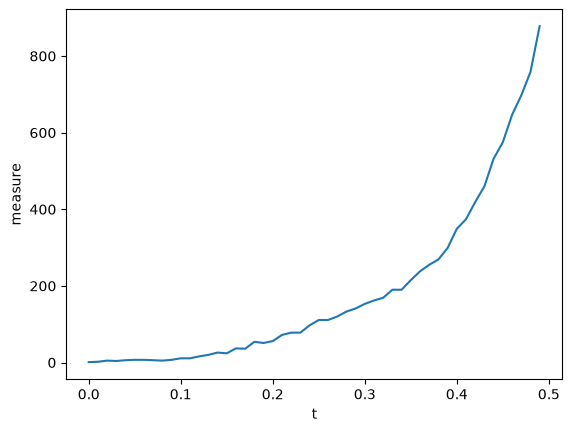

In [85]:
sns.lineplot(measures_df, x="t", y="measure")

In [68]:
idx = traj_X['t'].searchsorted(0.2, side='left') - 1
print(idx)
print(traj_X.loc[idx-1, :])

404
t         0.199833
value    56.000000
Name: 403, dtype: float64


In [ ]:
x = np.arange(len(traj_X))
x_smooth

array([    0,     1,     2, ..., 11169, 11170, 11171], shape=(11172,))

<Axes: xlabel='t', ylabel='value'>

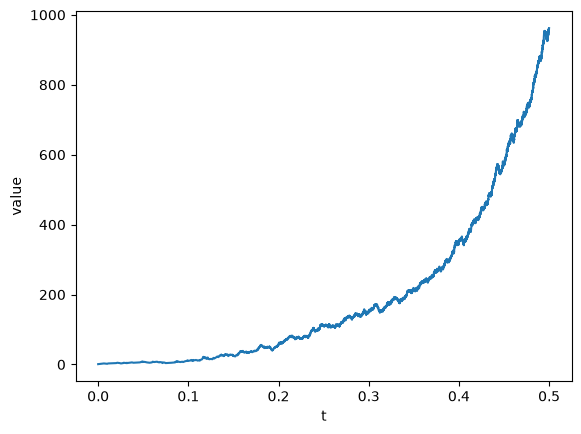

In [36]:
sns.lineplot(traj_X, x="t", y="value")